# Practical Machine Learning                                                                             
# Lab 1

## Exercises

#### Prerequisites

In [2]:
import numpy as np
import matplotlib.pyplot as plt 
from pathlib import Path
from PIL import Image as ImageModule

### 1.[Here](https://github.com//practical-ML-fmi/ML/raw/master/Data/lab1/images.zip), we have 8 images, read the images, flatten them, then store them in a numpy array. Before storing the images divide them by 255.
The numpy array should have the dimension equals to (8, 12288), in order to check the dimension use the $shape$ attribute.

In [3]:
 # write your code here
PATH_TO_IMG_DIR: Path = Path.cwd() / "images"

img_list: list[np.ndarray] = []

for path_to_curr_img in PATH_TO_IMG_DIR.iterdir():
    curr_img: ImageModule.Image = ImageModule.open(fp=path_to_curr_img)
    curr_img_arr: np.ndarray = np.array(object=curr_img)
    curr_img_flat_arr = curr_img_arr.flatten() / 255
    img_list.append(curr_img_flat_arr)

# img_obj_array: np.ndarray = np.array([np.array(Image.open(img)) for img in PATH_TO_IMG_DIR.iterdir()])

img_list_np: np.ndarray[np.ndarray] = np.array(img_list)


In [4]:
img_list_np.shape

(8, 12288)

In [5]:
img_list_np

array([[0.0627451 , 0.        , 0.00392157, ..., 0.28235294, 0.21176471,
        0.16862745],
       [0.17647059, 0.25098039, 0.34509804, ..., 0.48235294, 0.48235294,
        0.49803922],
       [0.2745098 , 0.29803922, 0.17647059, ..., 0.59215686, 0.62352941,
        0.37254902],
       ...,
       [0.03137255, 0.10196078, 0.03137255, ..., 0.00784314, 0.00392157,
        0.01176471],
       [0.05098039, 0.36078431, 0.56862745, ..., 0.4745098 , 0.65882353,
        0.75686275],
       [0.3372549 , 0.38431373, 0.17647059, ..., 0.78039216, 0.65882353,
        0.54509804]], shape=(8, 12288))

### 2. Compute the mean of the images. 

In [6]:
# write your code here
# mean_img: np.ndarray = np.mean(img_list_np, axis=0)
# mean_img
mean_img_arr = np.sum(img_list_np, axis=0) / 8
mean_img_arr

array([0.27254902, 0.34509804, 0.22745098, ..., 0.37696078, 0.40735294,
       0.33676471], shape=(12288,))

In [7]:
mean_img_arr = np.mean(img_list_np, axis=0)
mean_img_arr

array([0.27254902, 0.34509804, 0.22745098, ..., 0.37696078, 0.40735294,
       0.33676471], shape=(12288,))

### 3. Normalize the images by subtracting the mean from each image.

In [8]:
# write your code here
norm_img_arr = img_list_np - mean_img_arr
norm_img_arr

array([[-0.20980392, -0.34509804, -0.22352941, ..., -0.09460784,
        -0.19558824, -0.16813725],
       [-0.09607843, -0.09411765,  0.11764706, ...,  0.10539216,
         0.075     ,  0.16127451],
       [ 0.00196078, -0.04705882, -0.05098039, ...,  0.21519608,
         0.21617647,  0.03578431],
       ...,
       [-0.24117647, -0.24313725, -0.19607843, ..., -0.36911765,
        -0.40343137, -0.325     ],
       [-0.22156863,  0.01568627,  0.34117647, ...,  0.09754902,
         0.25147059,  0.42009804],
       [ 0.06470588,  0.03921569, -0.05098039, ...,  0.40343137,
         0.25147059,  0.20833333]], shape=(8, 12288))

### 4. [Here](https://github.com//practical-ML-fmi/ML/raw/master/Data/lab1/weights.zip), we have the weights and the bias for a perceptron that classifies the images in 4 classes. Use the weights (use np.load(‘path’) to load the weights) and the images (after normalization) to compute (y_hat) the predictions of the perceptron.  
  $$ y_{hat} = softmax(X * W + b) $$
  $$ X - input, W - weights, b - bias $$
  $$Softmax(z_i)=\frac{e^{z_i}}{\sum_{j=1}^{j=K} e^{z_j} }$$

In [54]:
# write your code here
PATH_TO_WEIGHT: Path = Path.cwd() / "coefs.npy"
PATH_TO_BIAS: Path = Path.cwd() / "bias.npy"

images = norm_img_arr
weights = np.load(PATH_TO_WEIGHT)
bias = np.load(PATH_TO_BIAS)

def softmax(z) -> float:
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z)

def predict(X, W, b) -> np.ndarray:
    return softmax(np.dot(X, W) + b)

y_hat = predict(images, weights, bias).argmax(axis=1)
y_hat

array([0, 0, 1, 1, 2, 2, 3, 2])

### 5. Let the ground-truth labels be y = [0, 0, 1, 1, 2,  2, 3,  3]. Compute the accuracy of the classifier (define a new function accuracy_score). 
$$Accuracy = \frac{1}{n} \sum_{i=1}^{j=n} y_{pred}^i == y_{true}^i$$

In [45]:
# write your code here 

gnd_truth = np.array([0, 0, 1, 1, 2, 2, 3, 3])

def accuracy(y_true, y_pred):
    is_correct = np.array(y_true == y_pred)
    return np.sum(is_correct) / is_correct.shape[0]

print(accuracy(gnd_truth, y_hat))

0.875


### 6. The labels of the classes are: (Cat - 0,  Dog - 1, Frog - 2,  Horse - 3), print the label for each prediction (use a dictionary). 


In [43]:
gnd_truth

[0, 0, 1, 1, 2, 2, 3, 3]

In [44]:
y_hat

array([0, 0, 1, 1, 2, 2, 3, 2])

In [47]:
# write your code here
mapping = {
    (0): "Cat",
    (1): "Dog",
    (2): "Frog",
    (3): "Horse"
}

for idx in range(y_hat.shape[0]):
    print(f"GROUND_TRUTH: {gnd_truth[idx]} = {mapping[(gnd_truth[idx])]} | PREDICTED: {y_hat[idx]} = {mapping[(y_hat[idx])]}")

GROUND_TRUTH: 0 = Cat | PREDICTED: 0 = Cat
GROUND_TRUTH: 0 = Cat | PREDICTED: 0 = Cat
GROUND_TRUTH: 1 = Dog | PREDICTED: 1 = Dog
GROUND_TRUTH: 1 = Dog | PREDICTED: 1 = Dog
GROUND_TRUTH: 2 = Frog | PREDICTED: 2 = Frog
GROUND_TRUTH: 2 = Frog | PREDICTED: 2 = Frog
GROUND_TRUTH: 3 = Horse | PREDICTED: 3 = Horse
GROUND_TRUTH: 3 = Horse | PREDICTED: 2 = Frog


### 7. Display the mean image (use imshow from Matplotlib).
#### Don’t forget to multiply the image by 255, then convert the image to uint8.

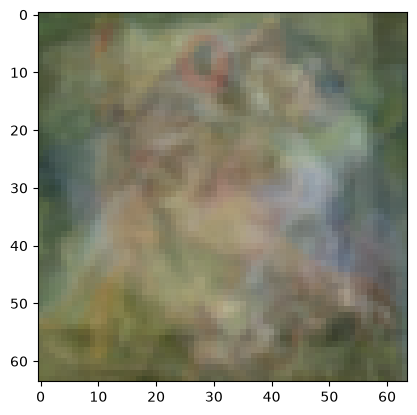

In [51]:
# write your code here
new_img = mean_img_arr.reshape((64, 64, 3)) * 255
plt.imshow(X=new_img.astype(np.uint8))

In [60]:
# Y = np.array([0, 0, 1, 1, 2, 2, 3, 3])
# Y = np.eye(4)[y]
# Y

In [61]:
# p_true = np.sum(Y * y_hat, axis=1)
# p_true

In [62]:
W_copy = weights.copy()
b_copy = bias.copy()

W_copy, b_copy

(array([[-0.02039216,  0.07607843, -0.01333333, -0.08745098],
        [-0.02078431,  0.05529412, -0.01294118, -0.02980392],
        [ 0.02352941, -0.01411765, -0.03137255,  0.08      ],
        ...,
        [-0.04578431,  0.0022549 ,  0.01941176,  0.01980392],
        [-0.05264706,  0.00284314,  0.01980392,  0.05588235],
        [-0.00245098, -0.03637255, -0.01392157,  0.10921569]],
       shape=(12288, 4)),
 array([-0.2, -0.6, -0.4, -2. ]))

In [ ]:
lr = {
    "loss_lr_1": 0.001,
    "loss_lr_2": 0.01,
    "loss_lr_3": 0.1
}

NUM_STEPS = 50


def cross_entropy(y_hat, Y):
    eps = 1e-15
    y_hat = np.clip(y_hat, eps, 1 - eps)

    return -np.mean(np.log(y_hat[np.arange(len(Y)), Y]))


def gradient_descent(X, Y, y_hat, W, b, lr):
    m = X.shape[0]

    dZ = y_hat.copy()
    dZ[np.arange(m), Y] -= 1

    d_W = X.T @ dZ / m
    d_b = np.sum(dZ, axis=0) / m

    W = W - lr * d_W
    b = b - lr * d_b

    return W, b


X = img_list_np
Y = gnd_truth.astype(int)

history_loss = {
    "loss_lr_1": [],
    "loss_lr_2": [],
    "loss_lr_3": []
}

for lr_name, lr_value in lr.items():
    W = W_copy.copy()
    b = b_copy.copy()

    for step in range(NUM_STEPS):
        y_hat = predict(X, W, b)

        loss = cross_entropy(y_hat=y_hat, Y=Y)

        history_loss[lr_name].append(loss)

        W, b = gradient_descent(
            X=X,
            Y=Y,
            y_hat=y_hat,
            W=W,
            b=b,
            lr=lr_value
        )

print(history_loss)

{'loss_lr_1': [np.float64(28.473648713241168), np.float64(28.465774201083345), np.float64(28.457899688928734), np.float64(28.450025176777483), np.float64(28.442150664629885), np.float64(28.43427615248614), np.float64(28.426401640346477), np.float64(28.418527128211174), np.float64(28.410652616080576), np.float64(28.402778103954883), np.float64(28.394903591834474), np.float64(28.387029079719703), np.float64(28.379154567610907), np.float64(28.371280055508503), np.float64(28.36340554341287), np.float64(28.35553103132448), np.float64(28.347656519243788), np.float64(28.339782007171294), np.float64(28.33190749510755), np.float64(28.324032983053115), np.float64(28.316158471008553), np.float64(28.30828395897455), np.float64(28.30040944695181), np.float64(28.29253493494105), np.float64(28.284660422942963), np.float64(28.276785910958548), np.float64(28.26891139898857), np.float64(28.26103688703397), np.float64(28.253162375095755), np.float64(28.24528786317505), np.float64(28.237413351272934), np.

C:\Users\user\AppData\Local\Temp\ipykernel_33140\1524272220.py:10: RuntimeWarning: overflow encountered in exp
  exp_z = np.exp(z)
C:\Users\user\AppData\Local\Temp\ipykernel_33140\1524272220.py:11: RuntimeWarning: invalid value encountered in divide
  return exp_z / np.sum(exp_z)


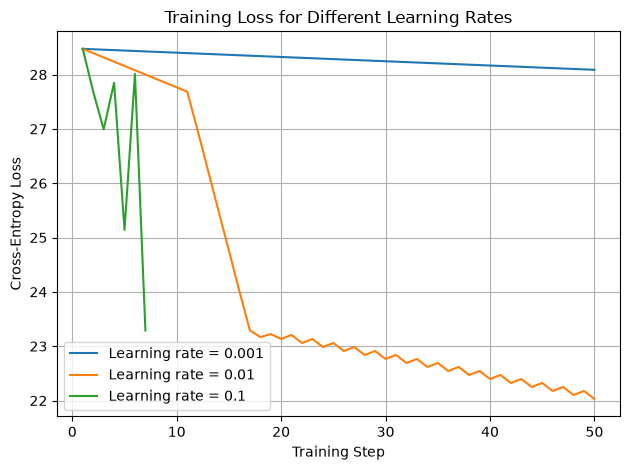

In [68]:
import matplotlib.pyplot as plt

for lr_name, losses in history_loss.items():
    plt.plot(
        range(1, NUM_STEPS + 1),
        losses,
        label=f"Learning rate = {lr[lr_name]}"
    )

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training Loss for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()